# INF-19 · 합성 이진 분류 데이터로 infer-ci 평가하기

## 목표
작은 합성 데이터와 단순 모델로 성능 지표·95% 신뢰구간을 계산하고, **같은 Accuracy에 Wilson과 Bootstrap BCa를 적용한 결과**를 비교한다. 실제 업무·의료 데이터가 아닌 교육용 실험이다.

## 설계와 사용 이유
- **합성 데이터 400개, 특징 6개:** 외부 파일 없이 생성 조건과 seed를 공개해 재실행할 수 있도록 선택했다. 400개는 교육용 실행 규모이며 통계적으로 권장되는 최소 표본 수라는 의미는 아니다.
- **약 70:30 클래스 비율:** Accuracy와 양성 클래스 성능을 함께 읽는 연습을 위한 설정이다. 양성 클래스는 숫자 1이며 실제 질병·업무 의미는 부여하지 않는다.
- **Logistic Regression:** INF-14에서도 사용한 모델 하나에 집중해 평가 코드를 짧게 유지한다. 최적 모델을 선정하거나 성능을 최대화하는 실험이 아니다.
- **75:25 층화 분할:** Train 300 / Test 100으로 나누고 클래스 비율을 비슷하게 유지한다. 표준화는 학습 데이터에서만 fit한다. 별도의 특징 선택과 튜닝은 수행하지 않는다.
- **DummyClassifier:** 학습 데이터의 다수 클래스만 예측하는 기준 모델과 점수를 비교해 Accuracy를 읽는 맥락을 제공한다. 모델 간 차이의 유의성을 검정하지 않는다.
- **Accuracy·Precision·Recall·binary F1:** 전체 정답 비율, 양성 예측의 정확성, 실제 양성 검출 비율, Precision·Recall의 조화를 각각 확인한다. 이진 지표의 양성 라벨은 1로 통일한다.
- **Wilson / Bootstrap BCa:** Accuracy·Precision·Recall의 비율형 구간은 Wilson으로, binary F1은 Bootstrap BCa로 계산한다. 같은 Accuracy에 BCa도 적용해 구간을 비교한다. 한 실험으로 어떤 구간 방법이 더 좋다고 결론 내리지 않는다.
- **95%·Bootstrap 3,000회·seed 42:** 구간 수준과 난수 설정을 명시한다. 반복 횟수는 교육용 실행 시간과 구간 관찰을 위한 선택이며 수렴이나 충분성이 검증된 최적값은 아니다.

## 재현 환경
INF-14에서 검증한 동일 환경(Python 3.11.9, infer-ci 0.2.1)을 재사용한다. 저장소 루트의 `requirements-inf14.txt`에 실제 패키지 버전과 SciPy wheel URL·해시가 기록되어 있다. 해당 파일은 macOS arm64 / Python 3.11 환경용이다. 다른 플랫폼에서는 대응하는 배포 파일을 선택해야 한다.

```bash
python3.11 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements-inf14.txt
python -m jupyter nbconvert --execute --to notebook --inplace notebooks/inf19_small_binary_evaluation.ipynb
```

### 가정과 한계
한 번의 합성 데이터 생성과 단일 Train/Test 분할을 사용한다. 관측 행은 독립 표본으로 취급한다. Bootstrap은 고정된 모델의 Test 정답·예측 쌍을 재표집하며 모델을 다시 학습하지 않는다. 따라서 실제 데이터의 대표성, 학습 과정의 변동, 여러 분할에 걸친 안정성을 입증하지 않는다.


## 실행 결과 핵심

- 코드 셀 8개를 위에서 아래로 실행했다. Test 100개 중 실제 양성은 32개였다.
- Logistic Regression Accuracy **0.7700**, 다수 클래스 기준 Accuracy **0.6800**였다. 관측 점수 차이는 +0.0900이며 유의성 검정은 수행하지 않았다.
- 양성 클래스 Precision **0.6667**, Recall **0.5625**, binary F1 **0.6102**였다. 실제 양성 32개 중 18개를 찾고 14개를 놓쳤다.
- 같은 Accuracy의 95% CI는 Wilson [0.6785, 0.8416], Bootstrap BCa [0.6800, 0.8400]였다. 이 한 번의 결과로 구간 방법의 우수성을 결론 내리지 않는다.
- infer-ci의 점추정값은 동일 정의의 scikit-learn 지표와 절대오차 1e-8 이내였고, 같은 seed의 Bootstrap Accuracy 구간이 재현되었다.


## 1. 환경과 실험 설정

아래 값을 고정한 뒤 Test 결과를 보고 모델 설정이나 임계값을 바꾸지 않는다.

In [1]:
%matplotlib inline
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from infer_ci import MetricEvaluator

SEED = 42
CONFIDENCE_LEVEL = 0.95
N_RESAMPLES = 3000
plt.rcParams.update({"figure.dpi": 130, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})
print("Python:", platform.python_version())
print("Platform:", platform.system(), platform.machine())
for name in ["infer-ci", "numpy", "scipy", "pandas", "scikit-learn", "matplotlib"]:
    print(f"{name}=={version(name)}")
print(f"Confidence={CONFIDENCE_LEVEL}; bootstrap resamples={N_RESAMPLES}; seed={SEED}")

Python: 3.11.9
Platform: Darwin arm64
infer-ci==0.2.1
numpy==2.2.6
scipy==1.15.3
pandas==2.3.3
scikit-learn==1.7.2
matplotlib==3.10.6
Confidence=0.95; bootstrap resamples=3000; seed=42


## 2. 합성 데이터 생성과 층화 분할

`make_classification`으로 실제 관측값이 아닌 교육용 데이터를 만든다. `stratify=y`는 Train과 Test의 클래스 비율을 비슷하게 유지한다. 특징 6개를 모두 사용하며 정답으로 특징을 고르는 단계는 없다.

In [2]:
X, y = make_classification(
    n_samples=400, n_features=6, n_informative=4, n_redundant=0,
    n_classes=2, weights=[0.7, 0.3], flip_y=0.03,
    class_sep=1.0, random_state=SEED,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED,
)
assert np.isfinite(X).all()
assert set(np.unique(y)) == {0, 1}
counts = pd.DataFrame({
    "All": np.bincount(y, minlength=2),
    "Train": np.bincount(y_train, minlength=2),
    "Test": np.bincount(y_test, minlength=2),
}, index=["Class 0", "Class 1 (positive)"])
display(counts)
print(f"Train shape: {X_train.shape}; Test shape: {X_test.shape}")

,All,Train,Test
Class 0,274,206,68
Class 1 (positive),126,94,32


Train shape: (300, 6); Test shape: (100, 6)


## 3. 학습 데이터에서만 표준화하고 모델 학습

Pipeline의 `fit(X_train, y_train)`이 표준화와 모델 학습을 학습 데이터에만 수행한다. Test는 `predict`에만 사용한다. 같은 학습 데이터로 다수 클래스 기준 모델을 만든다.

In [3]:
model = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# 표준화 평균이 학습 데이터에서 얻어졌는지 확인한다.
np.testing.assert_allclose(model.named_steps["scale"].mean_, X_train.mean(axis=0))
assert model.named_steps["scale"].n_samples_seen_ == len(X_train)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_baseline = baseline.predict(X_test)

def point_metrics(truth, prediction):
    return {
        "Accuracy": accuracy_score(truth, prediction),
        "Precision (positive=1)": precision_score(truth, prediction, pos_label=1, zero_division=0),
        "Recall (positive=1)": recall_score(truth, prediction, pos_label=1, zero_division=0),
        "F1 (binary, positive=1)": f1_score(truth, prediction, average="binary", pos_label=1, zero_division=0),
    }
point_table = pd.DataFrame({
    "Majority baseline": point_metrics(y_test, y_baseline),
    "Logistic Regression": point_metrics(y_test, y_pred),
})
display(point_table.style.format("{:.4f}"))
print("Baseline predicts only:", np.unique(y_baseline).tolist())

,Majority baseline,Logistic Regression
Accuracy,0.6800,0.7700
Precision (positive=1),0.0000,0.6667
Recall (positive=1),0.0000,0.5625
"F1 (binary, positive=1)",0.0000,0.6102


Baseline predicts only: [0]


## 4. 혼동행렬로 지표의 분모 확인

행은 실제 라벨, 열은 예측 라벨이다. Precision은 예측 양성 수, Recall은 실제 양성 수를 분모로 사용한다. 기준 모델은 양성을 예측하지 않으므로 비교 표의 Precision은 `zero_division=0`으로 0을 표시했다.

TN=59, FP=9, FN=14, TP=18; Test n=100
Predicted positives=27; Actual positives=32


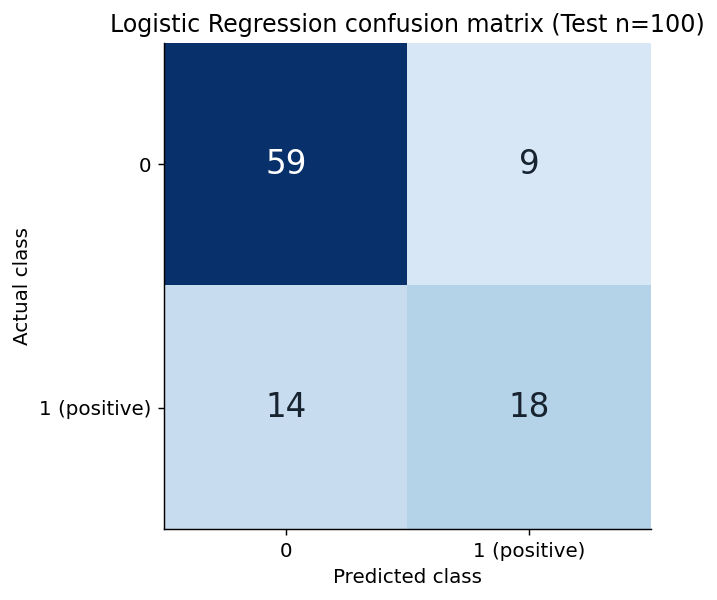

In [4]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}; Test n={cm.sum()}")
print(f"Predicted positives={tp + fp}; Actual positives={tp + fn}")
fig, ax = plt.subplots(figsize=(5.5, 4.5), layout="constrained")
ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(1, int(cm.max())))
for (i, j), count in np.ndenumerate(cm):
    ax.text(j, i, str(count), ha="center", va="center", fontsize=18,
            color="white" if count > cm.max() * 0.55 else "#182330")
ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted class", ylabel="Actual class",
       title=f"Logistic Regression confusion matrix (Test n={len(y_test)})")
ax.set_xticklabels(["0", "1 (positive)"])
ax.set_yticklabels(["0", "1 (positive)"])
ax.grid(False)
plt.show()

## 5. infer-ci로 지표와 95% 신뢰구간 계산

Accuracy·Precision·Recall은 Wilson 구간, F1은 `average="binary"`를 명시한 BCa 구간을 사용한다. Accuracy의 BCa 구간을 추가해 **같은 정답·예측·지표**에서 구간 계산 방법만 비교한다. 모든 지표에 Wilson을 일괄 적용하지 않는다.


In [5]:
evaluator = MetricEvaluator()
rows = []
settings = [
    ("Accuracy", "accuracy", "wilson", {}),
    ("Precision (positive=1)", "precision", "wilson", {}),
    ("Recall (positive=1)", "recall", "wilson", {}),
    ("F1 (binary, positive=1)", "f1", "bootstrap_bca", {"average": "binary"}),
    ("Accuracy", "accuracy", "bootstrap_bca", {}),
]
for label, metric, method, extra in settings:
    kwargs = dict(extra)
    if method == "bootstrap_bca":
        kwargs.update(n_resamples=N_RESAMPLES, random_state=SEED)
    score, (low, high) = evaluator.evaluate(
        y_true=y_test, y_pred=y_pred, task="classification", metric=metric,
        method=method, confidence_level=CONFIDENCE_LEVEL, **kwargs,
    )
    rows.append({"Metric": label, "Method": method, "Score": float(score),
                 "CI low": float(low), "CI high": float(high), "CI width": float(high - low)})
ci_table = pd.DataFrame(rows)
display(ci_table.style.format({column: "{:.4f}" for column in ["Score", "CI low", "CI high", "CI width"]}))

Bootstrap CI (BCA):   0%|          | 0/3101 [00:00<?]

Bootstrap CI (BCA):  15%|█▍        | 453/3101 [00:00<00:00]

Bootstrap CI (BCA):  30%|██▉       | 925/3101 [00:00<00:00]

Bootstrap CI (BCA):  45%|████▌     | 1403/3101 [00:00<00:00]

Bootstrap CI (BCA):  61%|██████    | 1894/3101 [00:00<00:00]

...

Bootstrap CI (BCA):  93%|█████████▎| 2878/3101 [00:00<00:00]

Bootstrap CI (BCA): 100%|██████████| 3101/3101 [00:00<00:00]

Bootstrap CI (BCA):   0%|          | 0/3101 [00:00<?]

Bootstrap CI (BCA): 100%|██████████| 3101/3101 [00:00<00:00]

,Metric,Method,Score,CI low,CI high,CI width
0,Accuracy,wilson,0.7700,0.6785,0.8416,0.1631
1,Precision (positive=1),wilson,0.6667,0.4782,0.8136,0.3353
2,Recall (positive=1),wilson,0.5625,0.3933,0.7183,0.3251
3,"F1 (binary, positive=1)",bootstrap_bca,0.6102,0.4528,0.7458,0.2929
4,Accuracy,bootstrap_bca,0.7700,0.6800,0.8400,0.1600


## 6. 지표 정의와 재현성 확인

infer-ci의 점추정값을 scikit-learn의 동일 정의 지표와 대조한다. 특히 F1은 양쪽 모두 binary로 고정한다. Bootstrap Accuracy를 같은 seed로 한 번 더 호출해 구간이 재현되는지 확인한다. 이는 계산 방법의 통계적 coverage 검증과는 구분한다.

라이브러리는 일부 비율의 분모에 `1e-7`을 더해 0 나눗셈을 방지한다. 따라서 scikit-learn과의 점추정 비교는 이 데이터에서 절대오차 `1e-8` 이내인지 확인하고 실제 차이도 표시한다.

In [6]:
reference = point_metrics(y_test, y_pred)
for row in rows:
    np.testing.assert_allclose(row["Score"], reference[row["Metric"]], rtol=0, atol=1e-8)
    assert np.isfinite([row["Score"], row["CI low"], row["CI high"]]).all()
    assert 0 <= row["CI low"] <= row["CI high"] <= 1

again_score, again_ci = evaluator.evaluate(
    y_true=y_test, y_pred=y_pred, task="classification", metric="accuracy",
    method="bootstrap_bca", confidence_level=CONFIDENCE_LEVEL,
    n_resamples=N_RESAMPLES, random_state=SEED,
)
acc_bca = ci_table[(ci_table["Metric"] == "Accuracy") & (ci_table["Method"] == "bootstrap_bca")].iloc[0]
np.testing.assert_allclose([again_score, *again_ci], [acc_bca["Score"], acc_bca["CI low"], acc_bca["CI high"]], rtol=0, atol=1e-12)
display(pd.DataFrame([{"Metric": r["Metric"], "Absolute difference from sklearn": abs(r["Score"] - reference[r["Metric"]])} for r in rows]))
print("PASS: point estimates match scikit-learn within 1e-8; CI bounds are finite and ordered.")
print("PASS: Bootstrap Accuracy CI repeats with the same seed in this environment.")

Bootstrap CI (BCA):   0%|          | 0/3101 [00:00<?]

Bootstrap CI (BCA): 100%|██████████| 3101/3101 [00:00<00:00]

,Metric,Absolute difference from sklearn
0,Accuracy,0.000000e+00
1,Precision (positive=1),2.469136e-09
2,Recall (positive=1),1.757813e-09
3,"F1 (binary, positive=1)",0.000000e+00
4,Accuracy,0.000000e+00


PASS: point estimates match scikit-learn within 1e-8; CI bounds are finite and ordered.
PASS: Bootstrap Accuracy CI repeats with the same seed in this environment.


## 7. 점수와 신뢰구간 시각화

첫 그래프는 네 지표의 점수와 구간을, 두 번째 그래프는 Accuracy에 대한 두 계산 방법의 구간을 보여준다. 가로축은 0~1의 동일 척도다. 구간이 좁다고 더 정확한 구간 계산법이라는 의미는 아니다.

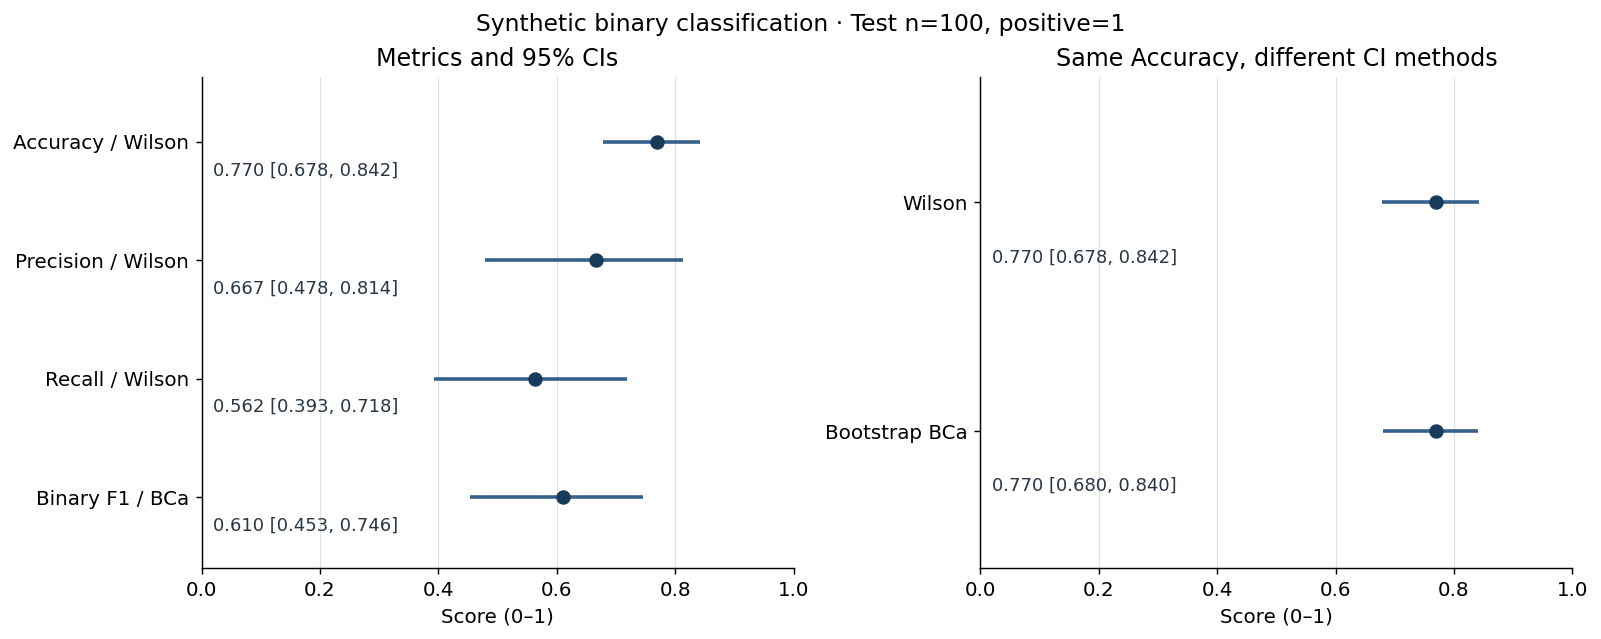

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), layout="constrained")
main_rows = ci_table.iloc[:4]
comparison = ci_table[ci_table["Metric"] == "Accuracy"]
for ax, table, labels, title in [
    (axes[0], main_rows, ["Accuracy / Wilson", "Precision / Wilson", "Recall / Wilson", "Binary F1 / BCa"], "Metrics and 95% CIs"),
    (axes[1], comparison, ["Wilson", "Bootstrap BCa"], "Same Accuracy, different CI methods"),
]:
    for position, (_, row) in enumerate(table.iterrows()):
        ax.hlines(position, row["CI low"], row["CI high"], color="#35618d", linewidth=2)
        ax.plot(row["Score"], position, marker="o", color="#183b5b", markersize=7)
        ax.text(0.02, position + 0.24, f'{row["Score"]:.3f} [{row["CI low"]:.3f}, {row["CI high"]:.3f}]',
                fontsize=10, va="center", color="#283644")
    ax.set(yticks=np.arange(len(table)), yticklabels=labels, xlim=(0, 1),
           ylim=(len(table) - 0.4, -0.55), xlabel="Score (0–1)", title=title)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#dce1e6", linewidth=0.7)
fig.suptitle(f"Synthetic binary classification · Test n={len(y_test)}, positive=1", fontsize=13)
plt.show()

## 8. 실행 결과 해석

아래 설명은 위 셀에서 실제로 계산한 값으로 생성한다.

In [8]:
acc = reference["Accuracy"]
baseline_acc = accuracy_score(y_test, y_baseline)
precision_value = reference["Precision (positive=1)"]
recall_value = reference["Recall (positive=1)"]
f1_value = reference["F1 (binary, positive=1)"]
w = ci_table.iloc[0]
b = ci_table.iloc[4]
display(Markdown(f"""
- Test **{len(y_test)}개**, 실제 양성 **{tp + fn}개**, 예측 양성 **{tp + fp}개**에서 평가했다.
- 다수 클래스 기준 모델의 Accuracy는 **{baseline_acc:.4f}**, Logistic Regression은 **{acc:.4f}**였다. 관측된 점수 차이는 **{acc - baseline_acc:+.4f}**이며 차이에 대한 유의성 검정은 수행하지 않았다.
- 양성 클래스 기준 Precision **{precision_value:.4f}**, Recall **{recall_value:.4f}**, binary F1 **{f1_value:.4f}**였다. 혼동행렬에서 FP={fp}, FN={fn}을 함께 확인할 수 있다.
- 같은 Accuracy의 95% Wilson 구간은 [{w['CI low']:.4f}, {w['CI high']:.4f}], BCa 구간은 [{b['CI low']:.4f}, {b['CI high']:.4f}]였다. 점수는 같아도 계산 방법에 따라 구간 경계가 달라질 수 있다.
- 두 구간의 폭은 Wilson **{w['CI width']:.4f}**, BCa **{b['CI width']:.4f}**였다. 구간 폭만으로 방법의 우수성이나 명목 신뢰수준 충족 여부를 판단하지 않는다.
"""))
# 기록용 요약은 파일을 추가 생성하지 않고 노트북 출력에 남긴다.
import json
summary = {"test_n": len(y_test), "positive_n": int(tp + fn),
           "confusion_matrix": cm.tolist(), "baseline_accuracy": float(baseline_acc),
           "metrics": rows}
print("RESULT_JSON=" + json.dumps(summary))


- Test **100개**, 실제 양성 **32개**, 예측 양성 **27개**에서 평가했다.
- 다수 클래스 기준 모델의 Accuracy는 **0.6800**, Logistic Regression은 **0.7700**였다. 관측된 점수 차이는 **+0.0900**이며 차이에 대한 유의성 검정은 수행하지 않았다.
- 양성 클래스 기준 Precision **0.6667**, Recall **0.5625**, binary F1 **0.6102**였다. 혼동행렬에서 FP=9, FN=14을 함께 확인할 수 있다.
- 같은 Accuracy의 95% Wilson 구간은 [0.6785, 0.8416], BCa 구간은 [0.6800, 0.8400]였다. 점수는 같아도 계산 방법에 따라 구간 경계가 달라질 수 있다.
- 두 구간의 폭은 Wilson **0.1631**, BCa **0.1600**였다. 구간 폭만으로 방법의 우수성이나 명목 신뢰수준 충족 여부를 판단하지 않는다.


RESULT_JSON={"test_n": 100, "positive_n": 32, "confusion_matrix": [[59, 9], [14, 18]], "baseline_accuracy": 0.68, "metrics": [{"Metric": "Accuracy", "Method": "wilson", "Score": 0.77, "CI low": 0.6784561697712622, "CI high": 0.8415673411969654, "CI width": 0.1631111714257032}, {"Metric": "Precision (positive=1)", "Method": "wilson", "Score": 0.6666666641975308, "CI low": 0.47824760507320074, "CI high": 0.8135673850128435, "CI width": 0.3353197799396428}, {"Metric": "Recall (positive=1)", "Method": "wilson", "Score": 0.5624999982421874, "CI low": 0.3932559113685198, "CI high": 0.7183466888495963, "CI width": 0.3250907774810765}, {"Metric": "F1 (binary, positive=1)", "Method": "bootstrap_bca", "Score": 0.6101694915254238, "CI low": 0.45283018867924524, "CI high": 0.7457627118644068, "CI width": 0.29293252318516155}, {"Metric": "Accuracy", "Method": "bootstrap_bca", "Score": 0.77, "CI low": 0.68, "CI high": 0.84, "CI width": 0.15999999999999992}]}


## 한계

- 합성 데이터의 단일 분할 결과이므로 실제 서비스 성능으로 일반화할 수 없다.
- 표본 수를 늘리면 항상 더 좋은 모델이 된다고 말할 수 없고, seed 고정은 데이터 대표성을 보장하지 않는다.
- Test 결과를 사용한 튜닝, 임계값 탐색, 모델 선택은 하지 않았다. 필요하면 학습 데이터 내부 교차검증 또는 별도 Validation으로 수행해야 한다.
- Bootstrap 3,000회의 수렴성은 검증하지 않았다. 재표집 수에 따른 구간 안정성이나 반복 분할·coverage 실험은 후속 과제다.
- Precision·Recall의 분모와 신뢰구간 폭을 함께 살펴봐야 한다. 본 실험이 최소 표본 수 기준을 정해주지는 않는다.


## 근거와 참고

- [원본 저장소 README](https://github.com/humblebeeai/infer-ci/blob/8dcaf9a866f9f745adc0c106b698cef9a30edef3/README.md)
- [infer-ci 평가 API](https://github.com/humblebeeai/infer-ci/blob/8dcaf9a866f9f745adc0c106b698cef9a30edef3/src/infer_ci/evaluator.py)
- [infer-ci binary 지표와 Wilson](https://github.com/humblebeeai/infer-ci/blob/8dcaf9a866f9f745adc0c106b698cef9a30edef3/src/infer_ci/binary_metrics.py)
- [infer-ci F1 averaging](https://github.com/humblebeeai/infer-ci/blob/8dcaf9a866f9f745adc0c106b698cef9a30edef3/src/infer_ci/takahashi_methods.py)
- [scikit-learn make_classification](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_classification.html)
- [scikit-learn Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [scikit-learn DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)

공식 문서의 stable 주소는 갱신될 수 있으며, 실제 사용 버전은 첫 실행 셀과 환경 파일에 기록했다.
